# Unit18_GNN_Overview | 圖神經網路(GNN)基礎範例

本 Notebook 使用 **合成圖資料(Synthetic Graph)**，以 TensorFlow/Keras **從零實作一個圖卷積網路(GCN)**，示範圖神經網路最核心的運算：

$$
H^{(k)} = \sigma\left( \hat{A}\, H^{(k-1)}\, W^{(k)} \right)
$$

並完成一個**半監督節點分類(Semi-Supervised Node Classification)** 任務。

## 目標
- 認識圖資料的矩陣表示：鄰接矩陣 $A$ 、度矩陣 $D$ 、特徵矩陣 $X$
- 親手建構正規化鄰接矩陣 $\hat{A} = \tilde{D}^{-1/2}\tilde{A}\tilde{D}^{-1/2}$
- 從零實作 GCN 層並堆疊成兩層 GCN 模型
- 以自訂訓練迴圈(masked loss)完成節點分類
- 比較 GCN 與忽略圖結構的 MLP，體會「結構資訊」的價值

> 本範例為搭配 `Unit18_GNN_Overview.md` 概述講義的基礎程式碼示範。


---
### 0. 環境設定
- 本範例使用合成圖資料，無需額外下載資料集。
- 使用 TensorFlow/Keras 實作 GCN，可在 Colab 或本地 CPU 環境執行(資料量小，CPU 即可)。

In [1]:
from pathlib import Path
import tensorflow as tf
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P4_Unit18_GNN_Overview'
SOURCE_DATA_DIR = 'gnn'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

if IN_COLAB:
    shortcut_path = '/content/ChemE-3590'
    try:
        os.remove(shortcut_path)
    except FileNotFoundError:
        pass
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    NOTEBOOK_DIR = Path(shortcut_path) / 'Part_4' / 'Unit18'
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
DATA_DIR = NOTEBOOK_DIR / 'data' / SOURCE_DATA_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'

for d in (NOTEBOOK_DIR, OUTPUT_DIR, DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 模型輸出目錄: {MODEL_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

# ========================================
# 檢查 GPU 狀態
# ========================================
print(f"\nTensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ 偵測到 GPU：{gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("△ 未偵測到 GPU，將使用 CPU(本範例資料量小，CPU 即可快速完成)。")


✓ 偵測到 Local 環境

✓ Notebook工作目錄: D:\MyGit\ChemE-3590\Part_4\Unit18
✓ 結果輸出目錄: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_GNN_Overview
✓ 模型輸出目錄: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_GNN_Overview\models
✓ 圖檔輸出目錄: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_GNN_Overview\figs

TensorFlow Version: 2.10.1
✓ 偵測到 GPU：/physical_device:GPU:0


---
### 1. 導入必要套件

In [2]:
# 基礎套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# sklearn 評估工具
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print(f"TensorFlow版本: {tf.__version__}")
print(f"Keras版本: {keras.__version__}")
print(f"NetworkX版本: {nx.__version__}")

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.rcParams['axes.unicode_minus'] = False


TensorFlow版本: 2.10.1
Keras版本: 2.10.0
NetworkX版本: 3.4


---
### 2. 圖資料準備

我們用 **隨機區塊模型(Stochastic Block Model, SBM)** 生成一張具有 **3 個社群(Community)** 的合成圖：

- **節點(Node)**：代表實體(可類比為分子中的原子，或製程中的感測器)
- **邊(Edge)**：同社群內連接機率高，跨社群連接機率低
- **節點特徵(Features)**：含**微弱**的類別訊號 + 隨機雜訊

目標是**節點分類**：預測每個節點屬於哪一個社群。由於特徵訊號很弱，模型必須善用**圖的連接結構**才能分類成功。

In [3]:
# ========================================
# 以隨機區塊模型(SBM)生成合成圖
# ========================================
N_PER = 30           # 每個社群的節點數
N_CLASSES = 3        # 社群(類別)數
N = N_PER * N_CLASSES # 總節點數
P_IN = 0.25          # 社群內連邊機率
P_OUT = 0.02         # 社群間連邊機率
F = 5                # 節點特徵維度

labels = np.repeat(np.arange(N_CLASSES), N_PER)
rng = np.random.default_rng(SEED)

# 建立鄰接矩陣 A (無向圖)
A = np.zeros((N, N), dtype='float32')
for i in range(N):
    for j in range(i + 1, N):
        p = P_IN if labels[i] == labels[j] else P_OUT
        if rng.random() < p:
            A[i, j] = 1.0
            A[j, i] = 1.0

# 節點特徵：微弱類別訊號(+0.5) + 標準常態雜訊
X = rng.normal(0, 1, size=(N, F)).astype('float32')
for c in range(N_CLASSES):
    X[labels == c, c] += 0.5

n_edges = int(A.sum() / 2)
print(f"節點數 N = {N}")
print(f"特徵維度 F = {F}")
print(f"類別(社群)數 = {N_CLASSES}")
print(f"邊數 = {n_edges}")
print(f"平均度(average degree) = {A.sum(axis=1).mean():.2f}")


節點數 N = 90
特徵維度 F = 5
類別(社群)數 = 3
邊數 = 393
平均度(average degree) = 8.73


### 2.1 圖結構視覺化

用 NetworkX 的 spring layout 畫出圖，節點顏色代表真實社群。

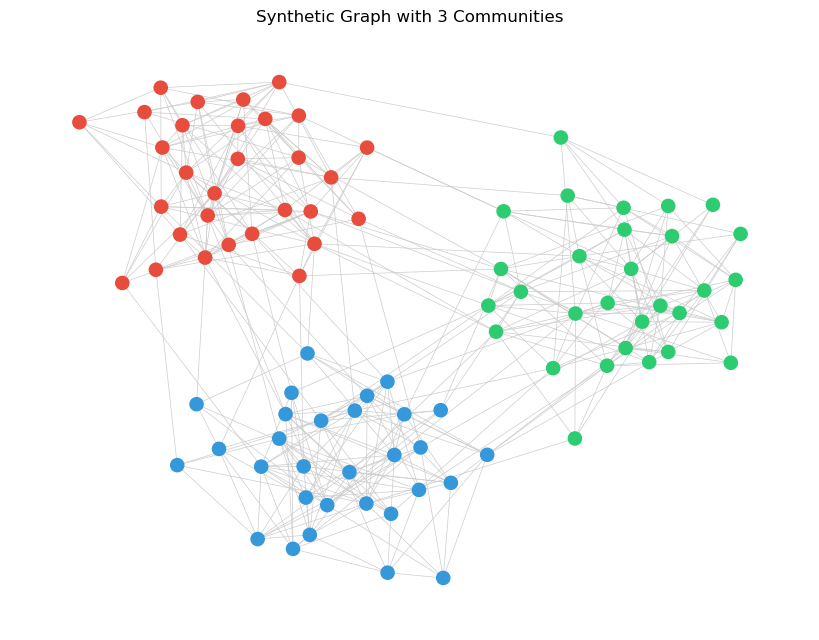

In [4]:
G = nx.from_numpy_array(A)
pos = nx.spring_layout(G, seed=SEED)

colors = ['#e74c3c', '#2ecc71', '#3498db']
node_colors = [colors[l] for l in labels]

plt.figure(figsize=(8, 6))
nx.draw(G, pos,
        node_color=node_colors,
        node_size=90,
        edge_color='#cccccc',
        width=0.5,
        with_labels=False)
plt.title('Synthetic Graph with 3 Communities')
plt.tight_layout()
plt.savefig(FIG_DIR / 'graph_structure.png', dpi=120, bbox_inches='tight')
plt.show()


### 2.2 建立正規化鄰接矩陣與訓練遮罩

依照 GCN 的公式建構正規化鄰接矩陣：

$$
\tilde{A} = A + I, \quad \hat{A} = \tilde{D}^{-1/2}\, \tilde{A}\, \tilde{D}^{-1/2}
$$

並建立**半監督**設定的訓練/測試遮罩(每類別僅 10 個節點有標籤可供訓練)。

In [5]:
# A_hat = D^{-1/2} (A + I) D^{-1/2}
A_tilde = A + np.eye(N, dtype='float32')
deg = A_tilde.sum(axis=1)
D_inv_sqrt = np.diag(1.0 / np.sqrt(deg)).astype('float32')
A_hat = (D_inv_sqrt @ A_tilde @ D_inv_sqrt).astype('float32')

# one-hot 標籤
Y = keras.utils.to_categorical(labels, N_CLASSES).astype('float32')

# 半監督遮罩：每類別取 10 個節點作為訓練標籤，其餘作為測試
train_mask = np.zeros(N, dtype=bool)
test_mask = np.zeros(N, dtype=bool)
for c in range(N_CLASSES):
    idx = np.where(labels == c)[0]
    rng.shuffle(idx)
    train_mask[idx[:10]] = True
    test_mask[idx[10:]] = True

print(f"訓練節點數 = {train_mask.sum()} (每類別 10 個)")
print(f"測試節點數 = {test_mask.sum()}")
print(f"A_hat shape = {A_hat.shape}, X shape = {X.shape}, Y shape = {Y.shape}")

# 轉為 TensorFlow 常數
X_tf = tf.constant(X)
A_tf = tf.constant(A_hat)
Y_tf = tf.constant(Y)
train_mask_tf = tf.constant(train_mask)
test_mask_tf = tf.constant(test_mask)


訓練節點數 = 30 (每類別 10 個)
測試節點數 = 60
A_hat shape = (90, 90), X shape = (90, 5), Y shape = (90, 3)


---
### 3. 從零實作 GCN 層

GCN 單層的傳播規則為：

$$
H' = \sigma\left( \hat{A}\, H\, W + b \right)
$$

其中 $\hat{A}$ 負責**聚合鄰居**(矩陣乘法等同於對每個節點的鄰居特徵加權求和)， $W$ 負責**特徵轉換**， $\sigma$ 為激活函數。下面以 Keras 自訂層實作。

In [6]:
class GCNLayer(layers.Layer):
    """圖卷積層: H' = activation( A_hat @ H @ W + b )"""

    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        # input_shape 為 [H_shape, A_hat_shape]
        feat_dim = int(input_shape[0][-1])
        self.w = self.add_weight(
            name='w', shape=(feat_dim, self.units),
            initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(
            name='b', shape=(self.units,),
            initializer='zeros', trainable=True)

    def call(self, inputs):
        H, A_hat = inputs
        # 先特徵轉換 (H @ W)，再鄰居聚合 (A_hat @ ...)
        support = tf.matmul(H, self.w)        # (N, units)
        out = tf.matmul(A_hat, support) + self.b  # (N, units)
        return self.activation(out)


# 快速測試一層的輸出維度
_test = GCNLayer(8, activation='relu')([X_tf, A_tf])
print(f"單層 GCN 輸出 shape: {_test.shape}  (應為 ({N}, 8))")


單層 GCN 輸出 shape: (90, 8)  (應為 (90, 8))


---
### 4. 建立兩層 GCN 模型

堆疊兩層 GCN(中間加 Dropout 防止過擬合)，用於節點分類：

- 第 1 層：輸入特徵 → 16 維隱藏表示(ReLU)，聚合 1-hop 鄰居
- 第 2 層：16 維 → 類別數的 logits，聚合 2-hop 鄰居

In [7]:
class GCN(keras.Model):
    def __init__(self, hidden=16, n_classes=3, dropout=0.5):
        super().__init__()
        self.gc1 = GCNLayer(hidden, activation='relu')
        self.drop = layers.Dropout(dropout)
        self.gc2 = GCNLayer(n_classes, activation=None)  # 輸出 logits

    def call(self, inputs, training=False):
        H, A_hat = inputs
        h = self.gc1([H, A_hat])
        h = self.drop(h, training=training)
        out = self.gc2([h, A_hat])
        return out


model = GCN(hidden=16, n_classes=N_CLASSES, dropout=0.5)
_ = model([X_tf, A_tf])  # 建立權重
model.summary()


Model: "gcn"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 gcn_layer_1 (GCNLayer)      multiple                  96        


 dropout (Dropout)           multiple                  0         


 gcn_layer_2 (GCNLayer)      multiple                  51        


Total params: 147


Trainable params: 147


Non-trainable params: 0


_________________________________________________________________


---
### 5. 訓練模型(自訂訓練迴圈)

節點分類是在**整張圖**上進行的，整張圖視為單一批次。我們使用 `tf.GradientTape` 自訂訓練迴圈，並以**訓練遮罩**計算 masked 交叉熵(只對有標籤的節點計算損失)。

In [8]:
optimizer = keras.optimizers.Adam(learning_rate=0.01)

def masked_softmax_ce(logits, labels_oh, mask):
    per = keras.losses.categorical_crossentropy(labels_oh, logits, from_logits=True)
    m = tf.cast(mask, tf.float32)
    return tf.reduce_sum(per * m) / tf.reduce_sum(m)

def masked_accuracy(logits, mask):
    pred = tf.argmax(logits, axis=1)
    true = tf.argmax(Y_tf, axis=1)
    correct = tf.cast(tf.equal(pred, true), tf.float32)
    m = tf.cast(mask, tf.float32)
    return float(tf.reduce_sum(correct * m) / tf.reduce_sum(m))

EPOCHS = 200
history = {'loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(1, EPOCHS + 1):
    with tf.GradientTape() as tape:
        logits = model([X_tf, A_tf], training=True)
        loss = masked_softmax_ce(logits, Y_tf, train_mask_tf)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

    logits_eval = model([X_tf, A_tf], training=False)
    tr = masked_accuracy(logits_eval, train_mask_tf)
    te = masked_accuracy(logits_eval, test_mask_tf)
    history['loss'].append(float(loss))
    history['train_acc'].append(tr)
    history['test_acc'].append(te)

    if epoch == 1 or epoch % 20 == 0:
        print(f"Epoch {epoch:3d} | loss={float(loss):.4f} | train_acc={tr:.3f} | test_acc={te:.3f}")

print("\n訓練完成！")


Epoch   1 | loss=1.1283 | train_acc=0.367 | test_acc=0.333


Epoch  20 | loss=0.8502 | train_acc=0.967 | test_acc=0.983


Epoch  40 | loss=0.4933 | train_acc=1.000 | test_acc=0.983


Epoch  60 | loss=0.2169 | train_acc=1.000 | test_acc=0.967


Epoch  80 | loss=0.0914 | train_acc=1.000 | test_acc=0.967


Epoch 100 | loss=0.1099 | train_acc=1.000 | test_acc=0.983


Epoch 120 | loss=0.0455 | train_acc=1.000 | test_acc=0.967


Epoch 140 | loss=0.0651 | train_acc=1.000 | test_acc=0.983


Epoch 160 | loss=0.0332 | train_acc=1.000 | test_acc=0.983


Epoch 180 | loss=0.0215 | train_acc=1.000 | test_acc=0.967


Epoch 200 | loss=0.0319 | train_acc=1.000 | test_acc=0.967

訓練完成！


### 5.1 訓練曲線

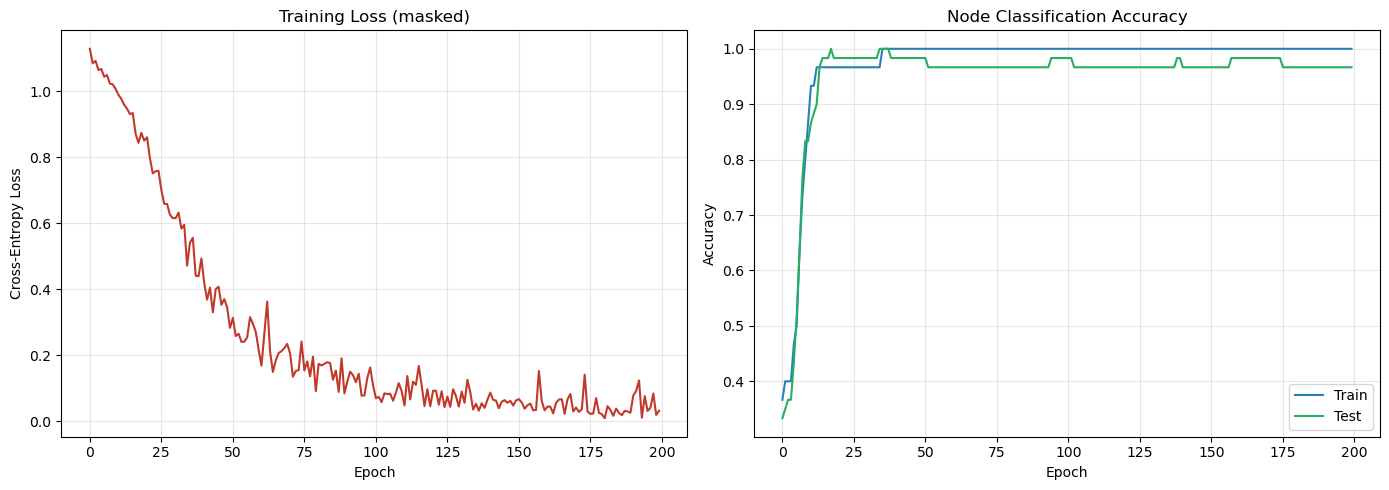

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['loss'], color='#c0392b')
axes[0].set_title('Training Loss (masked)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train', color='#2980b9')
axes[1].plot(history['test_acc'], label='Test', color='#27ae60')
axes[1].set_title('Node Classification Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 6. 模型評估與基線比較

我們將訓練好的 GCN 與一個**忽略圖結構的 MLP** 做比較。MLP 只看節點特徵，無法利用連接關係；由於特徵訊號微弱，GCN 應明顯勝出，凸顯「圖結構資訊」的價值。

In [10]:
# GCN 測試表現
logits = model([X_tf, A_tf], training=False).numpy()
gcn_pred = logits.argmax(axis=1)
gcn_test_acc = accuracy_score(labels[test_mask], gcn_pred[test_mask])
print(f"GCN 測試準確率 = {gcn_test_acc:.3f}\n")
print("GCN 分類報告(測試節點):")
print(classification_report(labels[test_mask], gcn_pred[test_mask],
                            target_names=[f'Community {c}' for c in range(N_CLASSES)]))

# 基線：忽略圖結構的 MLP
mlp = keras.Sequential([
    layers.Input((F,)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(N_CLASSES)
])
mlp.compile(optimizer=keras.optimizers.Adam(0.01),
            loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
            metrics=['accuracy'])
mlp.fit(X[train_mask], labels[train_mask], epochs=200, verbose=0)
mlp_pred = mlp.predict(X, verbose=0).argmax(axis=1)
mlp_test_acc = accuracy_score(labels[test_mask], mlp_pred[test_mask])

print(f"\n{'='*40}")
print(f"GCN (利用圖結構)  測試準確率 = {gcn_test_acc:.3f}")
print(f"MLP (忽略圖結構)  測試準確率 = {mlp_test_acc:.3f}")
print(f"{'='*40}")
print("→ GCN 透過聚合鄰居資訊，在特徵微弱時仍能準確分類。")


GCN 測試準確率 = 0.967

GCN 分類報告(測試節點):
              precision    recall  f1-score   support

 Community 0       1.00      0.90      0.95        20
 Community 1       0.91      1.00      0.95        20
 Community 2       1.00      1.00      1.00        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60




GCN (利用圖結構)  測試準確率 = 0.967
MLP (忽略圖結構)  測試準確率 = 0.400
→ GCN 透過聚合鄰居資訊，在特徵微弱時仍能準確分類。


### 6.1 混淆矩陣

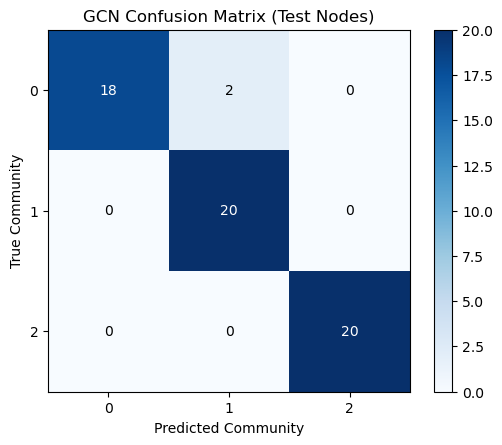

In [11]:
cm = confusion_matrix(labels[test_mask], gcn_pred[test_mask])

plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap='Blues')
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, int(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.title('GCN Confusion Matrix (Test Nodes)')
plt.xlabel('Predicted Community')
plt.ylabel('True Community')
plt.xticks(range(N_CLASSES))
plt.yticks(range(N_CLASSES))
plt.colorbar()
plt.tight_layout()
plt.savefig(FIG_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()


---
### 7. 圖層級讀出(Readout)示範

節點分類是**節點層級**任務。若要做**圖層級**任務(如預測整個分子的性質)，需將所有節點表示彙整成單一「圖表示向量」。下面以 **mean pooling** 示範讀出步驟：

$$
h_G = \frac{1}{N}\sum_{v \in V} h_v
$$

In [12]:
# 取第一層 GCN 的節點表示作為節點 embedding
node_embeddings = model.gc1([X_tf, A_tf]).numpy()   # shape = (N, hidden)

# 圖層級讀出：對所有節點做 mean pooling
graph_embedding = node_embeddings.mean(axis=0)

print(f"節點表示矩陣 shape = {node_embeddings.shape}")
print(f"圖層級表示向量 shape = {graph_embedding.shape}")
print(f"圖表示向量 h_G = {np.round(graph_embedding, 3)}")
print("\n在真實的分子性質預測中，h_G 會再接一個 MLP，輸出該分子的性質值(如沸點、溶解度)。")


節點表示矩陣 shape = (90, 16)
圖層級表示向量 shape = (16,)
圖表示向量 h_G = [0.646 0.667 0.749 0.476 0.38  0.    0.5   0.    0.329 0.393 0.667 0.584
 0.559 0.449 0.594 0.795]

在真實的分子性質預測中，h_G 會再接一個 MLP，輸出該分子的性質值(如沸點、溶解度)。


---
### 8. 模型權重儲存

In [13]:
# 儲存 GCN 模型權重 (TensorFlow checkpoint 格式)
weights_path = MODEL_DIR / 'gcn_node_classifier'
model.save_weights(str(weights_path))
print(f"✓ GCN 模型權重已儲存至: {weights_path}.*")

# 示範：重建模型並載入權重
reloaded = GCN(hidden=16, n_classes=N_CLASSES, dropout=0.5)
_ = reloaded([X_tf, A_tf])
reloaded.load_weights(str(weights_path))
reload_pred = reloaded([X_tf, A_tf], training=False).numpy().argmax(axis=1)
reload_acc = accuracy_score(labels[test_mask], reload_pred[test_mask])
print(f"✓ 重新載入後測試準確率 = {reload_acc:.3f} (應與原模型一致)")


✓ GCN 模型權重已儲存至: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_GNN_Overview\models\gcn_node_classifier.*
✓ 重新載入後測試準確率 = 0.967 (應與原模型一致)


---
### 9. 總結

本 Notebook 完成了以下內容：

1. **圖資料準備**：以隨機區塊模型(SBM)生成含 3 社群的合成圖，並視覺化
2. **矩陣表示**：建構鄰接矩陣 $A$ 與正規化鄰接矩陣 $\hat{A} = \tilde{D}^{-1/2}\tilde{A}\tilde{D}^{-1/2}$
3. **從零實作 GCN 層**：以 Keras 自訂層實作 $H' = \sigma(\hat{A} H W + b)$
4. **堆疊兩層 GCN**：完成半監督節點分類
5. **自訂訓練迴圈**：以 masked 交叉熵只對有標籤節點計算損失
6. **基線比較**：GCN(利用圖結構) 明顯優於忽略結構的 MLP
7. **圖層級讀出**：示範 mean pooling 將節點表示彙整為圖表示

#### 核心收穫
- GCN 的本質就是一行公式： $H^{(k)} = \sigma(\hat{A} H^{(k-1)} W^{(k)})$
- $\hat{A}$ 負責**聚合鄰居**， $W$ 負責**特徵轉換**
- 當節點特徵資訊不足時，**圖結構**提供了關鍵的額外資訊

#### 延伸練習
- 調整 `P_IN` / `P_OUT`，觀察社群分離程度對準確率的影響
- 嘗試堆疊更多層 GCN，觀察是否出現**過度平滑(over-smoothing)**
- 改用 GAT(注意力)或 GraphSAGE 架構
- 以 RDKit 將真實分子(SMILES)轉為圖，進行分子性質預測

---

**課程資訊**
- 課程名稱：AI在化工上之應用
- 課程單元：Unit18 - GNN Overview 圖神經網路概論
- 課程製作：逢甲大學 化工系 智慧程序系統工程實驗室
- 授課教師：莊曜禎 助理教授
- 更新日期：2026-11-15

**課程授權 [CC BY-NC-SA 4.0]**
 - 本教材遵循 [創用CC 姓名標示-非商業性-相同方式分享 4.0 國際 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.zh) 授權。
